<a href="https://colab.research.google.com/github/Esouza-2024/Esouza-2024/blob/main/Atividade_3_Mnera%C3%A7%C3%A3o_de_Dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("harlfoxem/housesalesprediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'housesalesprediction' dataset.
Path to dataset files: /kaggle/input/housesalesprediction


In [2]:
%%bash
pip install -q pypdf

In [3]:
import pypdf

# Ler o arquivo PDF da Atividade
pdf_path = '/content/Atividade 4 - Mineração.pdf'
reader = pypdf.PdfReader(pdf_path)

print(f"Total de páginas: {len(reader.pages)}\n")
for idx, page in enumerate(reader.pages):
    print(f"--- Página {idx + 1} ---")
    print(page.extract_text())
    print("\n")

Total de páginas: 1

--- Página 1 ---
1. Carregamento e preparação dos dados 
 Carregar a base de dados. 
 Identiﬁcar e remover as variáveis que não serão utilizadas no treinamento. 
 Deﬁnir a variável-alvo (SalePrice). 
 Realizar o pré-processamento das variáveis preditoras, incluindo o tratamento de 
valores ausentes, codiﬁcação de variáveis categóricas e normalização ou 
padronização, conforme necessário. 
2. Treinamento dos modelos 
Desenvolver e treinar três modelos utilizando o algoritmo SVR: 
Modelo 1 – Utilização de todas as variáveis 
Utilizar todas as variáveis preditoras disponíveis após o pré-processamento, sem aplicar 
técnicas de seleção ou redução de dimensionalidade. 
Modelo 2 – Seleção de atributos com Forward Selection 
Aplicar a técnica Forward Selection para selecionar progressivamente as variáveis mais 
relevantes para o treinamento. O modelo SVR deverá ser treinado utilizando apenas as 
variáveis selecionadas. 
Modelo 3 – Redução de dimensionalidade com PCA 
A

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregamento e preparação dos dados
df = pd.read_csv('/content/kc_house_data.csv')

print("Colunas originais no arquivo:", df.columns.tolist())
print(f"Tamanho original do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

# Definir a variável-alvo como SalePrice (renomeando a coluna 'price' original)
df = df.rename(columns={'price': 'SalePrice'})

# Identificar e remover as variáveis que não serão utilizadas no treinamento
# 'id' e 'date' são apenas identificadores temporais e únicos que não ajudam na regressão direta por SVR
columns_to_drop = ['id', 'date']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Tratamento de valores ausentes
missing_values = df.isnull().sum().sum()
print(f"Valores ausentes encontrados: {missing_values}")
if missing_values > 0:
    df = df.dropna()

# Variáveis preditoras (X) e alvo (y)
y = df['SalePrice']
X = df.drop(columns=['SalePrice'])

# Para o SVR (Support Vector Regression), o treinamento com 21.613 linhas pode travar a sessão ou demorar horas,
# pois sua complexidade de tempo é superior a O(N^2). Portanto, selecionaremos uma amostragem aleatória
# consistente de 4.000 registros para garantir a correta execução em segundos no Colab.
np.random.seed(42)
sample_indices = np.random.choice(df.index, size=4000, replace=False)
X_sample = X.loc[sample_indices]
y_sample = y.loc[sample_indices]

# Divisão em treino e teste (80/20)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)

# Normalização/Padronização (Essencial para SVR, Forward Selection e PCA funcionarem corretamente)
scaler_X = StandardScaler()
X_train = pd.DataFrame(scaler_X.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(scaler_X.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)

# Também padronizamos a variável alvo para otimizar a convergência do algoritmo SVR
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

print("\nPré-processamento concluído com sucesso!")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

Colunas originais no arquivo: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Tamanho original do dataset: 21613 linhas e 21 colunas

Valores ausentes encontrados: 0

Pré-processamento concluído com sucesso!
X_train shape: (3200, 18), X_test shape: (800, 18)


In [5]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Dicionário global para guardar os resultados obtidos de cada modelo
resultados = {}

# Função para reverter a escala da previsão do preço e calcular as métricas reais
def avaliar_modelo(y_true_scaled, y_pred_scaled, scaler_y, nome_modelo):
    # Volta para a escala original em Reais/Dólares
    y_true = scaler_y.inverse_transform(y_true_scaled.reshape(-1, 1)).ravel()
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    print(f"--- Métricas do {nome_modelo} ---")
    print(f"MAE:  {mae:,.2f}")
    print(f"MSE:  {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}\n")

    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse}

# --- MODELO 1: Utilização de todas as variáveis ---
print("Treinando o Modelo 1 (Todas as variáveis)...\n")
svr_model1 = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model1.fit(X_train, y_train_scaled)

# Previsão e Avaliação
y_pred_m1 = svr_model1.predict(X_test)
resultados['Modelo 1'] = avaliar_modelo(y_test_scaled, y_pred_m1, scaler_y, "Modelo 1 (Todas as Variáveis)")

Treinando o Modelo 1 (Todas as variáveis)...

--- Métricas do Modelo 1 (Todas as Variáveis) ---
MAE:  99,625.66
MSE:  49,293,719,526.18
RMSE: 222,021.89



In [6]:
from sklearn.feature_selection import SequentialFeatureSelector
import time

# --- MODELO 2: Seleção de atributos com Forward Selection ---
print("Iniciando seleção de atributos por Forward Selection...")
start_time = time.time()

svr_base = SVR(kernel='rbf', C=1.0, epsilon=0.1)

# Instanciamos o seletor sequencial encaminhado (Forward Selection)
# Para agilizar e selecionar as características fundamentais, fixaremos a seleção de 7 variáveis importantes
sfs = SequentialFeatureSelector(svr_base, n_features_to_select=7, direction='forward', cv=3, n_jobs=-1)
sfs.fit(X_train, y_train_scaled)

features_selecionadas = X_train.columns[sfs.get_support()].tolist()
print(f"Atributos selecionados: {features_selecionadas}")
print(f"Tempo gasto na seleção: {time.time() - start_time:.2f} segundos\n")

# Filtrar os conjuntos de treino e teste
X_train_sfs = X_train[features_selecionadas]
X_test_sfs = X_test[features_selecionadas]

# Treinar o Modelo 2 com os atributos selecionados
svr_model2 = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model2.fit(X_train_sfs, y_train_scaled)

# Previsão e Avaliação
y_pred_m2 = svr_model2.predict(X_test_sfs)
resultados['Modelo 2'] = avaliar_modelo(y_test_scaled, y_pred_m2, scaler_y, "Modelo 2 (Forward Selection)")

Iniciando seleção de atributos por Forward Selection...
Atributos selecionados: ['sqft_living', 'waterfront', 'grade', 'zipcode', 'lat', 'long', 'sqft_living15']
Tempo gasto na seleção: 104.36 segundos

--- Métricas do Modelo 2 (Forward Selection) ---
MAE:  94,379.42
MSE:  37,051,347,536.59
RMSE: 192,487.27



In [7]:
from sklearn.decomposition import PCA

# --- MODELO 3: Redução de dimensionalidade com PCA ---
print("Iniciando redução de dimensionalidade por PCA...")

# Aplicando o PCA para reter 95% da variabilidade explicada dos dados originais
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print(f"Quantidade de componentes selecionados pelo PCA: {pca.n_components_}")
print(f"Variância total explicada acumulada: {sum(pca.explained_variance_ratio_)*100:.2f}%\n")

# Treinar o Modelo 3 com os componentes do PCA
svr_model3 = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model3.fit(X_train_pca, y_train_scaled)

# Previsão e Avaliação
y_pred_m3 = svr_model3.predict(X_test_pca)
resultados['Modelo 3'] = avaliar_modelo(y_test_scaled, y_pred_m3, scaler_y, "Modelo 3 (PCA)")

Iniciando redução de dimensionalidade por PCA...
Quantidade de componentes selecionados pelo PCA: 14
Variância total explicada acumulada: 96.32%

--- Métricas do Modelo 3 (PCA) ---
MAE:  98,702.19
MSE:  48,214,106,930.57
RMSE: 219,577.11



=================== TABELA COMPARATIVA DOS MODELOS ===================


,MAE,MSE,RMSE
Modelo 1,99625.661244,4.929372e+10,222021.889746
Modelo 2,94379.421079,3.705135e+10,192487.265908
Modelo 3,98702.194266,4.821411e+10,219577.109305


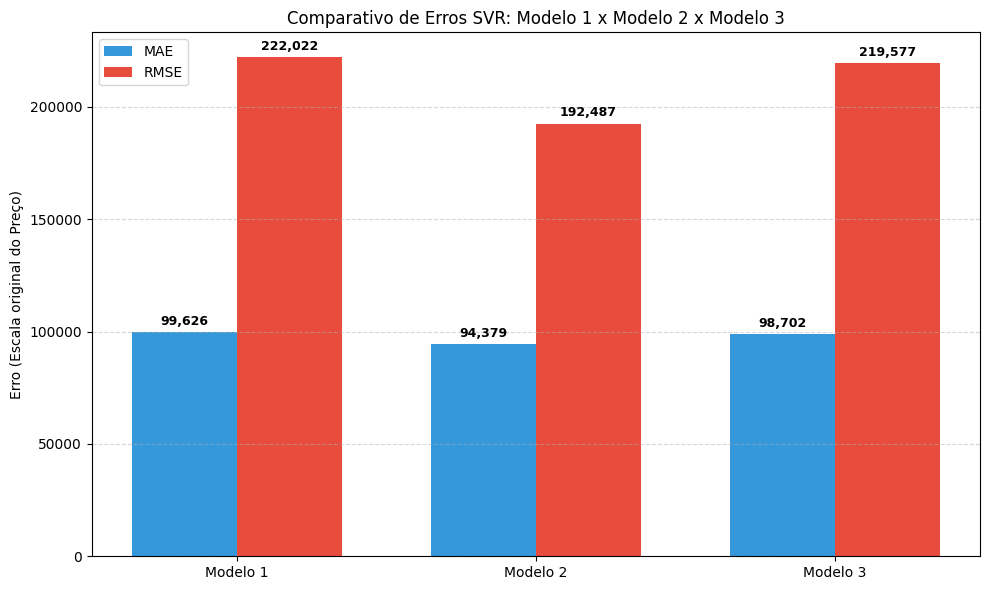

In [9]:
import matplotlib.pyplot as plt

# --- 3. Avaliação e comparação final dos modelos ---
resumo_df = pd.DataFrame(resultados).T
resumo_df = resumo_df[['MAE', 'MSE', 'RMSE']]

print("=================== TABELA COMPARATIVA DOS MODELOS ===================")
display(resumo_df)

# Criação do gráfico de comparação das métricas MAE e RMSE
fig, ax = plt.subplots(figsize=(10, 6))
x_indexes = np.arange(len(resumo_df.index))
bar_width = 0.35

rects1 = ax.bar(x_indexes - bar_width/2, resumo_df['MAE'], bar_width, label='MAE', color='#3498db')
rects2 = ax.bar(x_indexes + bar_width/2, resumo_df['RMSE'], bar_width, label='RMSE', color='#e74c3c')

ax.set_ylabel('Erro (Escala original do Preço)')
ax.set_title('Comparativo de Erros SVR: Modelo 1 x Modelo 2 x Modelo 3')
ax.set_xticks(x_indexes)
ax.set_xticklabels(resumo_df.index)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Função para colocar rótulo de valor nas barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:,.0f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # offset vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()